# 05 — Fusion training (GSAF + ablations)

Trains the **Gated Stream Attention Fusion (GSAF)** model on NewsCLIPpings train,
validates on NewsCLIPpings val, evaluates on:

- NewsCLIPpings test  (in-distribution)
- MMFakeBench val + test  (OOD, mixed-source forgery)
- VERITE test  (OOD, real-world)

It also trains four ablations to isolate the contribution of each component:

| Ablation     | Removes                              |
|--------------|--------------------------------------|
| `no_a`       | Stream A (entity grounding)          |
| `no_b`       | Stream B (CLIP representation)       |
| `no_c`       | Stream C (NLI evidence stance)       |
| `mlp_fusion` | Replaces gating with a vanilla MLP   |
| `default`    | Full GSAF                            |

## Outputs

- `cache/fusion/fusion_model.pt`  — best default-config checkpoint
- `cache/fusion/fusion_predictions.csv` — per-pair predictions for every eval split
- `cache/fusion/fusion_thresholds.json` — per-dataset threshold tuned on val
- `cache/fusion/fusion_train_history.csv` — training curves
- `paper/tables/fusion_results.csv`  — main results table
- `paper/tables/ablation_results.csv` — ablation table
- `paper/figures/fusion_summary_bar.png`
- `paper/figures/fusion_gate_distribution.png`  *(interpretability)*
- `paper/figures/fusion_confusion_<dataset>.png`
- `paper/figures/fusion_roc_<dataset>.png`

## Hardware

Designed for an RTX 4060 Ti (8 GB) but trivially CPU-runnable too — the model
has ~8K parameters and the feature matrix fits in memory (~25 MB).


In [1]:
# === ENVIRONMENT ===
from pathlib import Path
import sys, os, json, time, copy, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print(f"Python      : {sys.version.split()[0]}")
print(f"PyTorch     : {torch.__version__}")
print(f"CUDA avail  : {torch.cuda.is_available()}")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"GPU         : {torch.cuda.get_device_name(0)}")
    print(f"VRAM        : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
print(f"Device      : {DEVICE}")

def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "data").exists() and (q / "src").exists():
            return q
    raise RuntimeError("Could not find repo root.")

ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))

from src.utils.paths import FUSION_CACHE, FIGURES, TABLES
FUSION_CACHE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# Re-import the model module fresh so re-runs see the latest src/models/fusion.py
import importlib
if "src.models.fusion" in sys.modules:
    importlib.reload(sys.modules["src.models.fusion"])
from src.models.fusion import build_fusion_model

print("\nROOT          :", ROOT)
print("FUSION_CACHE  :", FUSION_CACHE)


Python      : 3.13.13
PyTorch     : 2.6.0+cu124
CUDA avail  : True
GPU         : NVIDIA GeForce RTX 4060 Ti
VRAM        : 8.6 GB
Device      : cuda

ROOT          : E:\eve-rag
FUSION_CACHE  : E:\eve-rag\cache\fusion


In [2]:
# === HYPERPARAMETERS ===
SEED            = 42
HIDDEN_DIM      = 32
DROPOUT         = 0.3
LR              = 1e-3
WEIGHT_DECAY    = 1e-4
BATCH_SIZE      = 1024
MAX_EPOCHS      = 60
EARLY_STOP_PAT  = 8
NUM_WORKERS     = 0   # tiny tensors — no benefit from workers
GRAD_CLIP       = 1.0

torch.manual_seed(SEED)
np.random.seed(SEED)


In [3]:
# === LOAD FUSION FEATURES + SCHEMA ===
feat_csv = FUSION_CACHE / "fusion_features_all.csv"
schema_path = FUSION_CACHE / "feature_schema.json"
if not feat_csv.exists() or not schema_path.exists():
    raise FileNotFoundError(
        f"Missing fusion artefacts: run fusion_module.ipynb first.\n"
        f"  expected: {feat_csv}\n  expected: {schema_path}"
    )

with open(schema_path) as f:
    schema = json.load(f)

A_FEATS = schema["stream_a_features"]
B_FEATS = schema["stream_b_features"]
C_FEATS = schema["stream_c_features"]
N_A, N_B, N_C = len(A_FEATS), len(B_FEATS), len(C_FEATS)
print(f"Stream feature dims  : A={N_A}  B={N_B}  C={N_C}  (total={N_A+N_B+N_C})")

df = pd.read_csv(feat_csv, low_memory=False)
df["pair_id"] = df["pair_id"].astype(str)
print(f"Fusion table shape   : {df.shape}")
print(f"Datasets             : {df['dataset'].value_counts().to_dict()}")
print(f"Splits               : {df['split'].value_counts().to_dict()}")
print(f"Label balance (all)  : {df['label'].value_counts().to_dict()}")


Stream feature dims  : A=12  B=11  C=7  (total=30)
Fusion table shape   : (97361, 35)
Datasets             : {'newsclippings': 85360, 'mmfakebench': 11000, 'verite': 1001}
Splits               : {'train': 71072, 'test': 18265, 'val': 8024}
Label balance (all)  : {1: 51043, 0: 46318}


In [4]:
# === DEFINE TRAIN / VAL / EVAL SPLITS ===
# Mixed-domain training (Fix A): add half of mmfakebench_val to the training
# pool so the gate sees a distribution where Stream C is the strong signal.
# The other half of mmfakebench_val is held out for threshold tuning.
from sklearn.model_selection import train_test_split

NC_TRAIN_FILTER = (df["dataset"] == "newsclippings") & (df["split"] == "train")
NC_VAL_FILTER   = (df["dataset"] == "newsclippings") & (df["split"] == "val")
MMFB_VAL_FILTER = (df["dataset"] == "mmfakebench")   & (df["split"] == "val")

# Deterministic 50/50 stratified split of mmfakebench_val (by label).
# Manual implementation: pandas 3.0's PyArrow-backed string columns aren't
# compatible with sklearn.train_test_split's internal indexing.
mmfb_val_df = df[MMFB_VAL_FILTER].reset_index(drop=True)
_rng = np.random.default_rng(SEED)
mmfb_train_set, mmfb_tune_set = set(), set()
for _lbl in sorted(mmfb_val_df["label"].unique().tolist()):
    _sub_pids = mmfb_val_df.loc[mmfb_val_df["label"] == _lbl, "pair_id"].astype(str).tolist()
    _rng.shuffle(_sub_pids)
    _half = len(_sub_pids) // 2
    mmfb_train_set.update(_sub_pids[:_half])
    mmfb_tune_set.update(_sub_pids[_half:])
print(f"MMFakeBench val split: "
      f"{len(mmfb_train_set)} → train, {len(mmfb_tune_set)} → tune")

# Compose the training pool: all NewsCLIPpings train + MMFakeBench val (half).
train_df = pd.concat([
    df[NC_TRAIN_FILTER],
    df[MMFB_VAL_FILTER & df["pair_id"].isin(mmfb_train_set)],
], ignore_index=True)

# Validation = NewsCLIPpings val only (early-stopping signal stays clean for
# comparison with the previous in-distribution run).
val_df = df[NC_VAL_FILTER].reset_index(drop=True)

# Eval splits: replace mmfakebench_val with mmfakebench_val_tune (held-out half).
EVAL_SPLITS = {
    "newsclippings_val":     NC_VAL_FILTER,
    "newsclippings_test":    (df["dataset"] == "newsclippings") & (df["split"] == "test"),
    "mmfakebench_val_tune":  MMFB_VAL_FILTER & df["pair_id"].isin(mmfb_tune_set),
    "mmfakebench_test":      (df["dataset"] == "mmfakebench")   & (df["split"] == "test"),
    "verite_test":           (df["dataset"] == "verite")        & (df["split"] == "test"),
}

print(f"\nTraining    : {len(train_df):,} rows  (pos rate = {train_df['label'].mean():.3f})")
print(f"  ├─ NC train     : {(train_df['dataset']=='newsclippings').sum():,}")
print(f"  └─ MMFB val(½)  : {(train_df['dataset']=='mmfakebench').sum():,}")
print(f"Validation  : {len(val_df):,} rows  (pos rate = {val_df['label'].mean():.3f})  (NC val — early stopping)")
for name, mask in EVAL_SPLITS.items():
    sub = df[mask]
    print(f"  {name:24s} : {len(sub):>6,} rows  (pos rate = {sub['label'].mean():.3f})")

MMFakeBench val split: 500 → train, 500 → tune

Training    : 71,572 rows  (pos rate = 0.501)
  ├─ NC train     : 71,072
  └─ MMFB val(½)  : 500
Validation  : 7,024 rows  (pos rate = 0.500)  (NC val — early stopping)
  newsclippings_val        :  7,024 rows  (pos rate = 0.500)
  newsclippings_test       :  7,264 rows  (pos rate = 0.500)
  mmfakebench_val_tune     :    500 rows  (pos rate = 0.700)
  mmfakebench_test         : 10,000 rows  (pos rate = 0.700)
  verite_test              :  1,001 rows  (pos rate = 0.662)


In [5]:
# === STANDARDIZE (fit on train) + ZERO-IMPUTE MISSING ===
ALL_FEATS = A_FEATS + B_FEATS + C_FEATS

# Compute per-feature mean/std using only TRAIN rows and only non-NaN values.
train_X = train_df[ALL_FEATS]
mu  = train_X.mean(axis=0, skipna=True)
sig = train_X.std(axis=0,  skipna=True).replace(0, 1.0).fillna(1.0)
mu  = mu.fillna(0.0)

def standardize(frame):
    X = frame[ALL_FEATS].copy()
    X = (X - mu) / sig
    X = X.fillna(0.0)  # zero-impute AFTER standardization (= population mean)
    return X.astype(np.float32).values

train_X_np = standardize(train_df)
val_X_np   = standardize(val_df)
print(f"train X shape: {train_X_np.shape}  (after standardize+impute)")
print(f"val   X shape: {val_X_np.shape}")

# Save scaler so any downstream notebook can load it identically
scaler_path = FUSION_CACHE / "feature_scaler.json"
with open(scaler_path, "w") as f:
    json.dump({
        "feature_order": ALL_FEATS,
        "mean": mu.tolist(),
        "std":  sig.tolist(),
    }, f, indent=2)
print(f"Wrote {scaler_path}")


train X shape: (71572, 30)  (after standardize+impute)
val   X shape: (7024, 30)
Wrote E:\eve-rag\cache\fusion\feature_scaler.json


In [6]:
# === DATASETS / DATALOADERS ===
class StreamFeatureDataset(Dataset):
    """Wraps a standardized feature matrix and label vector."""

    def __init__(self, X: np.ndarray, y: np.ndarray, n_a: int, n_b: int, n_c: int):
        assert X.shape[1] == n_a + n_b + n_c
        self.X_a = torch.from_numpy(X[:, :n_a]).float()
        self.X_b = torch.from_numpy(X[:, n_a:n_a + n_b]).float()
        self.X_c = torch.from_numpy(X[:, n_a + n_b:]).float()
        self.y   = torch.from_numpy(y.astype(np.float32))

    def __len__(self):
        return self.y.shape[0]

    def __getitem__(self, i):
        return self.X_a[i], self.X_b[i], self.X_c[i], self.y[i]


def make_loader(frame, X_np, batch_size, shuffle):
    y = frame["label"].astype(int).values
    ds = StreamFeatureDataset(X_np, y, N_A, N_B, N_C)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      num_workers=NUM_WORKERS, drop_last=False)


train_loader = make_loader(train_df, train_X_np, BATCH_SIZE, shuffle=True)
val_loader   = make_loader(val_df,   val_X_np,   BATCH_SIZE, shuffle=False)
print(f"Train loader: {len(train_loader)} batches of {BATCH_SIZE}")
print(f"Val   loader: {len(val_loader)} batches of {BATCH_SIZE}")


Train loader: 70 batches of 1024
Val   loader: 7 batches of 1024


In [7]:
# === TRAINING LOOP ===
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


def evaluate_loader(model, loader):
    """Run inference, return concatenated (logits, scores, labels, gates)."""
    model.eval()
    all_log, all_lab, all_gates = [], [], []
    with torch.no_grad():
        for x_a, x_b, x_c, y in loader:
            x_a = x_a.to(DEVICE); x_b = x_b.to(DEVICE); x_c = x_c.to(DEVICE)
            out = model(x_a, x_b, x_c, return_gates=True)
            logits, gates = out
            all_log.append(logits.cpu().numpy())
            all_gates.append(gates.cpu().numpy())
            all_lab.append(y.numpy())
    logits = np.concatenate(all_log)
    scores = 1.0 / (1.0 + np.exp(-logits))   # sigmoid
    labels = np.concatenate(all_lab).astype(int)
    gates  = np.concatenate(all_gates)
    return logits, scores, labels, gates


def train_one_config(ablation, max_epochs=MAX_EPOCHS, patience=EARLY_STOP_PAT, verbose=True):
    """Train one model config; return best model (cpu state_dict) and history."""
    torch.manual_seed(SEED)
    model = build_fusion_model(N_A, N_B, N_C, hidden_dim=HIDDEN_DIM,
                               ablation=ablation, dropout=DROPOUT).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.BCEWithLogitsLoss()

    history = []
    best_auroc = -1.0
    best_state = None
    bad_epochs = 0
    t0 = time.time()

    for epoch in range(1, max_epochs + 1):
        model.train()
        running_loss, n = 0.0, 0
        for x_a, x_b, x_c, y in train_loader:
            x_a = x_a.to(DEVICE); x_b = x_b.to(DEVICE)
            x_c = x_c.to(DEVICE); y = y.to(DEVICE)
            opt.zero_grad()
            logits = model(x_a, x_b, x_c)
            loss = crit(logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            running_loss += loss.item() * y.size(0); n += y.size(0)
        train_loss = running_loss / max(n, 1)

        _, val_scores, val_labels, _ = evaluate_loader(model, val_loader)
        val_pred = (val_scores >= 0.5).astype(int)
        val_acc = accuracy_score(val_labels, val_pred)
        val_f1  = f1_score(val_labels, val_pred, zero_division=0)
        val_auc = roc_auc_score(val_labels, val_scores) if len(np.unique(val_labels)) > 1 else float("nan")

        history.append({
            "ablation": ablation or "default", "epoch": epoch,
            "train_loss": round(train_loss, 5),
            "val_acc": round(val_acc * 100, 2), "val_f1": round(val_f1 * 100, 2),
            "val_auroc": round(val_auc * 100, 2),
        })
        if verbose:
            print(f"  [{ablation or 'default':10s}] epoch {epoch:>3d} "
                  f"train_loss={train_loss:.4f}  "
                  f"val_acc={val_acc*100:5.2f}  val_f1={val_f1*100:5.2f}  val_auroc={val_auc*100:5.2f}")

        # Early stopping on val AUROC
        if val_auc > best_auroc + 1e-4:
            best_auroc = val_auc
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                if verbose:
                    print(f"  ↳ early stop after {epoch} epochs (no AUROC improvement for {patience}).")
                break

    elapsed = time.time() - t0
    if verbose:
        print(f"  best val AUROC = {best_auroc*100:.2f}  ({elapsed:.1f}s)")
    return best_state, history, best_auroc


In [8]:
# === TRAIN DEFAULT GSAF ===
print(">>> Training default GSAF\n")
default_state, default_hist, default_best_auc = train_one_config(ablation=None)

# Save default model
ckpt_path = FUSION_CACHE / "fusion_model.pt"
torch.save({
    "state_dict": default_state,
    "config": {"hidden_dim": HIDDEN_DIM, "dropout": DROPOUT,
               "n_a": N_A, "n_b": N_B, "n_c": N_C, "ablation": None},
    "feature_order": ALL_FEATS,
    "best_val_auroc": default_best_auc,
}, ckpt_path)
print(f"\nSaved default model to {ckpt_path}")

# Save training history
hist_df = pd.DataFrame(default_hist)
hist_df.to_csv(FUSION_CACHE / "fusion_train_history.csv", index=False)
print(f"Saved {FUSION_CACHE / 'fusion_train_history.csv'}")


>>> Training default GSAF

  [default   ] epoch   1 train_loss=0.6601  val_acc=65.58  val_f1=63.06  val_auroc=72.59
  [default   ] epoch   2 train_loss=0.6200  val_acc=66.03  val_f1=63.40  val_auroc=73.41
  [default   ] epoch   3 train_loss=0.6100  val_acc=66.57  val_f1=65.27  val_auroc=73.91
  [default   ] epoch   4 train_loss=0.6057  val_acc=66.93  val_f1=64.78  val_auroc=74.27
  [default   ] epoch   5 train_loss=0.6033  val_acc=66.84  val_f1=63.24  val_auroc=74.44
  [default   ] epoch   6 train_loss=0.6024  val_acc=67.34  val_f1=64.61  val_auroc=74.53
  [default   ] epoch   7 train_loss=0.6000  val_acc=67.55  val_f1=65.56  val_auroc=74.64
  [default   ] epoch   8 train_loss=0.6003  val_acc=67.38  val_f1=65.46  val_auroc=74.65
  [default   ] epoch   9 train_loss=0.5986  val_acc=67.47  val_f1=64.75  val_auroc=74.67
  [default   ] epoch  10 train_loss=0.5983  val_acc=67.68  val_f1=65.75  val_auroc=74.70
  [default   ] epoch  11 train_loss=0.5966  val_acc=67.85  val_f1=66.70  val_auroc=

In [9]:
# === PER-DATASET THRESHOLD TUNING ===
def predict_split(model, frame):
    """Standardize a frame, run inference, return scores+labels+gates."""
    X = standardize(frame)
    loader = make_loader(frame, X, BATCH_SIZE, shuffle=False)
    return evaluate_loader(model, loader)


def tune_threshold(scores, labels, n=201):
    """Pick threshold that maximizes macro-F1 on the given (scores, labels)."""
    if len(np.unique(labels)) < 2:
        return 0.5
    grid = np.linspace(0.05, 0.95, n)
    best_thr, best_f1 = 0.5, -1.0
    for t in grid:
        pred = (scores >= t).astype(int)
        f = f1_score(labels, pred, average="macro", zero_division=0)
        if f > best_f1:
            best_f1, best_thr = f, t
    return float(best_thr)


# Reload best default model for thresholding.
model = build_fusion_model(N_A, N_B, N_C, hidden_dim=HIDDEN_DIM,
                           ablation=None, dropout=DROPOUT).to(DEVICE)
model.load_state_dict(default_state)
model.eval()

# Tune on val splits where available; map test → corresponding val threshold.
# Note: mmfakebench_val_tune is the held-out half of mmfb_val (the other half
# is now in training).
THRESHOLD_MAP = {
    "newsclippings_val":     "newsclippings_val",
    "newsclippings_test":    "newsclippings_val",
    "mmfakebench_val_tune":  "mmfakebench_val_tune",
    "mmfakebench_test":      "mmfakebench_val_tune",
    # VERITE has no val split — fall back to NewsCLIPpings val threshold.
    "verite_test":           "newsclippings_val",
}

cached_preds = {}
for name, mask in EVAL_SPLITS.items():
    sub = df[mask].reset_index(drop=True)
    if len(sub) == 0:
        continue
    _, scores, labels, gates = predict_split(model, sub)
    cached_preds[name] = {"frame": sub, "scores": scores,
                          "labels": labels, "gates": gates}

thresholds = {}
for tune_split in ["newsclippings_val", "mmfakebench_val_tune"]:
    if tune_split in cached_preds:
        c = cached_preds[tune_split]
        thr = tune_threshold(c["scores"], c["labels"])
        thresholds[tune_split] = thr

thresholds["default"] = 0.5
with open(FUSION_CACHE / "fusion_thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=2)
print("Tuned thresholds:")
for k, v in thresholds.items():
    print(f"  {k:24s}: {v:.3f}")

Tuned thresholds:
  newsclippings_val       : 0.482
  mmfakebench_val_tune    : 0.486
  default                 : 0.500


In [10]:
# === EVALUATE DEFAULT ON ALL SPLITS ===
def metrics_at_threshold(scores, labels, thr):
    pred = (scores >= thr).astype(int)
    out = {
        "thr": round(float(thr), 3),
        "acc":       round(accuracy_score(labels, pred) * 100, 2),
        "f1":        round(f1_score(labels, pred, zero_division=0) * 100, 2),
        "f1_macro":  round(f1_score(labels, pred, average="macro", zero_division=0) * 100, 2),
    }
    if len(np.unique(labels)) > 1:
        out["auroc"] = round(roc_auc_score(labels, scores) * 100, 2)
    else:
        out["auroc"] = float("nan")
    return out


pred_rows = []
for name, c in cached_preds.items():
    sub = c["frame"]; scores = c["scores"]; labels = c["labels"]
    tune_key = THRESHOLD_MAP.get(name, "default")
    thr_default = 0.5
    thr_tuned   = thresholds.get(tune_key, 0.5)

    for tag, thr in [("default", thr_default), ("tuned", thr_tuned)]:
        m = metrics_at_threshold(scores, labels, thr)
        pred_rows.append({"model": "GSAF", "ablation": "none",
                          "dataset": name, "tuning": tag, **m})

results = pd.DataFrame(pred_rows)
print("Default GSAF results:")
display(results)


Default GSAF results:


,model,ablation,dataset,tuning,thr,acc,f1,f1_macro,auroc
0,GSAF,none,newsclippings_val,default,0.500,68.99,67.25,68.90,76.01
1,GSAF,none,newsclippings_val,tuned,0.482,69.15,68.47,69.13,76.01
2,GSAF,none,newsclippings_test,default,0.500,68.68,66.88,68.59,76.32
3,GSAF,none,newsclippings_test,tuned,0.482,69.01,68.34,69.00,76.32
4,GSAF,none,mmfakebench_val_tune,default,0.500,80.80,85.80,78.08,89.92
5,GSAF,none,mmfakebench_val_tune,tuned,0.486,82.00,86.84,79.18,89.92
6,GSAF,none,mmfakebench_test,default,0.500,78.28,84.28,74.57,87.83
7,GSAF,none,mmfakebench_test,tuned,0.486,78.27,84.41,74.28,87.83
8,GSAF,none,verite_test,default,0.500,62.64,76.33,43.85,48.13
9,GSAF,none,verite_test,tuned,0.482,62.54,76.34,43.21,48.13


In [11]:
# === SAVE PER-PAIR PREDICTIONS ===
all_pred_frames = []
for name, c in cached_preds.items():
    out = c["frame"][["pair_id", "dataset", "split", "label", "has_image"]].copy()
    out["score"]   = c["scores"]
    out["gate_a"]  = c["gates"][:, 0] if c["gates"].shape[1] >= 1 else np.nan
    out["gate_b"]  = c["gates"][:, 1] if c["gates"].shape[1] >= 2 else np.nan
    out["gate_c"]  = c["gates"][:, 2] if c["gates"].shape[1] >= 3 else np.nan
    out["eval_split"] = name
    out["model"]   = "GSAF_default"
    all_pred_frames.append(out)

pred_df = pd.concat(all_pred_frames, ignore_index=True)
pred_df.to_csv(FUSION_CACHE / "fusion_predictions.csv", index=False)
print(f"Wrote {FUSION_CACHE / 'fusion_predictions.csv'}  ({len(pred_df):,} rows)")


Wrote E:\eve-rag\cache\fusion\fusion_predictions.csv  (25,789 rows)


In [12]:
# === TRAIN ABLATIONS ===
ABLATIONS = ["no_a", "no_b", "no_c", "mlp_fusion"]
ablation_states = {}
ablation_rows = []

# Re-evaluate the default model with the tuned thresholds for the ablation table
def eval_state(state, ablation):
    m = build_fusion_model(N_A, N_B, N_C, hidden_dim=HIDDEN_DIM,
                           ablation=ablation, dropout=DROPOUT).to(DEVICE)
    m.load_state_dict(state); m.eval()
    rows = []
    for name, mask in EVAL_SPLITS.items():
        sub = df[mask].reset_index(drop=True)
        if len(sub) == 0: continue
        _, scores, labels, _ = predict_split(m, sub)
        thr_key = THRESHOLD_MAP.get(name, "default")
        thr = thresholds.get(thr_key, 0.5)
        met = metrics_at_threshold(scores, labels, thr)
        rows.append({"ablation": ablation or "default", "dataset": name, **met})
    return rows

# Default already trained
ablation_rows.extend(eval_state(default_state, None))

for abl in ABLATIONS:
    print(f"\n>>> Training ablation: {abl}\n")
    state, hist, best_auc = train_one_config(ablation=abl, verbose=False)
    ablation_states[abl] = state
    rows = eval_state(state, abl)
    ablation_rows.extend(rows)
    print(f"  best val AUROC = {best_auc*100:.2f}")

ablation_df = pd.DataFrame(ablation_rows)
print("\nAblation results (tuned thresholds):")
display(ablation_df.pivot_table(index="ablation", columns="dataset",
                                 values=["acc", "auroc"], aggfunc="first"))



>>> Training ablation: no_a

  best val AUROC = 74.29

>>> Training ablation: no_b

  best val AUROC = 51.82

>>> Training ablation: no_c

  best val AUROC = 74.95

>>> Training ablation: mlp_fusion

  best val AUROC = 76.03

Ablation results (tuned thresholds):


acc                                          \
dataset    mmfakebench_test mmfakebench_val_tune newsclippings_test   
ablation                                                              
default               78.27                 82.0              69.01   
mlp_fusion            63.57                 61.2              68.42   
no_a                  62.30                 62.0              67.30   
no_b                  70.84                 71.8              49.97   
no_c                  62.50                 61.6              68.27   

                                                    auroc  \
dataset    newsclippings_val verite_test mmfakebench_test   
ablation                                                    
default                69.15       62.54            87.83   
mlp_fusion             68.92       65.83            65.96   
no_a                   67.51       64.34            65.24   
no_b                   50.58       65.73            65.27   
no_c                   67.95       65.93            62.87   

                                                                      \
dataset    mmfakebench_val_tune newsclippings_test newsclippings_val   
ablation                                                               
default                   89.92              76.32             76.01   
mlp_fusion                62.43              76.26             76.03   
no_a                      61.19              75.23             74.29   
no_b                      65.54              52.49             51.82   
no_c                      61.50              75.47             74.95   

                        
dataset    verite_test  
ablation                
default          48.13  
mlp_fusion       48.54  
no_a             47.37  
no_b             48.96  
no_c             48.13

In [13]:
# === SAVE PAPER TABLES ===
fusion_results_path = TABLES / "fusion_results.csv"
ablation_results_path = TABLES / "ablation_results.csv"

results.to_csv(fusion_results_path, index=False)
ablation_df.to_csv(ablation_results_path, index=False)
print(f"Wrote {fusion_results_path}")
print(f"Wrote {ablation_results_path}")


Wrote E:\eve-rag\paper\tables\fusion_results.csv
Wrote E:\eve-rag\paper\tables\ablation_results.csv


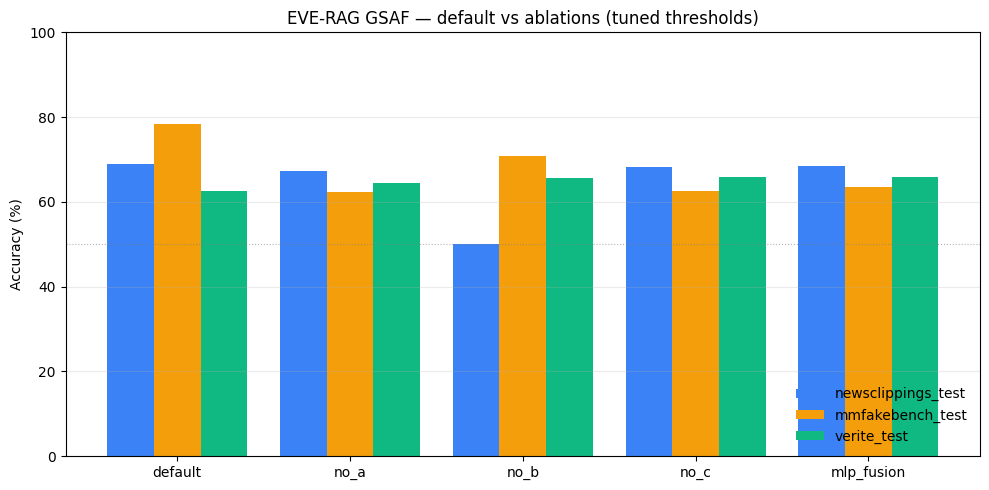

Saved E:\eve-rag\paper\figures\fusion_summary_bar.png


In [14]:
# === FIGURE: ALL-MODELS BAR CHART ===
plot_df = ablation_df[ablation_df["dataset"].isin(
    ["newsclippings_test", "mmfakebench_test", "verite_test"])].copy()
order = ["default", "no_a", "no_b", "no_c", "mlp_fusion"]
ds_order = ["newsclippings_test", "mmfakebench_test", "verite_test"]
colors = {"newsclippings_test": "#3b82f6", "mmfakebench_test": "#f59e0b",
          "verite_test": "#10b981"}

fig, ax = plt.subplots(figsize=(10, 5))
width = 0.27; x = np.arange(len(order))
for i, d in enumerate(ds_order):
    vals = [plot_df[(plot_df["ablation"] == a) & (plot_df["dataset"] == d)]["acc"].mean()
            for a in order]
    ax.bar(x + (i - 1) * width, vals, width, label=d, color=colors[d])
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel("Accuracy (%)"); ax.set_ylim(0, 100)
ax.axhline(50, color="gray", ls=":", lw=0.8, alpha=0.6)
ax.set_title("EVE-RAG GSAF — default vs ablations (tuned thresholds)")
ax.legend(loc="lower right", frameon=False); ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
out = FIGURES / "fusion_summary_bar.png"
plt.savefig(out, dpi=180, bbox_inches="tight"); plt.show()
print(f"Saved {out}")


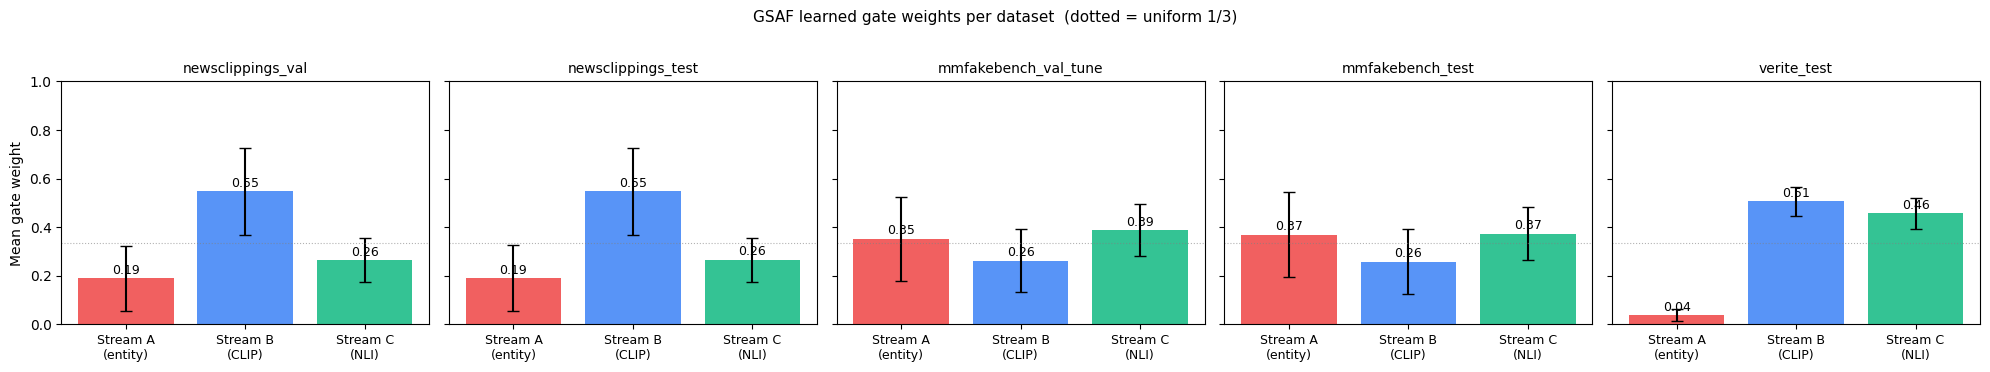

Saved E:\eve-rag\paper\figures\fusion_gate_distribution.png


In [15]:
# === FIGURE: GATE DISTRIBUTION (interpretability) ===
# For the default model on each eval split, plot the mean (and IQR) of
# gates over (Stream A, Stream B, Stream C). This shows which stream the
# model has learned to trust per dataset — a key claim in the paper.
fig, axes = plt.subplots(1, len(cached_preds), figsize=(4 * len(cached_preds), 3.6),
                         sharey=True)
if len(cached_preds) == 1:
    axes = [axes]
stream_names = ["Stream A\n(entity)", "Stream B\n(CLIP)", "Stream C\n(NLI)"]

for ax, (name, c) in zip(axes, cached_preds.items()):
    G = c["gates"]
    means = G.mean(axis=0); stds = G.std(axis=0)
    ax.bar(range(3), means, yerr=stds, capsize=4,
           color=["#ef4444", "#3b82f6", "#10b981"], alpha=0.85)
    ax.set_xticks(range(3)); ax.set_xticklabels(stream_names, fontsize=9)
    ax.set_title(name, fontsize=10); ax.set_ylim(0, 1.0)
    ax.axhline(1/3, color="gray", ls=":", lw=0.8, alpha=0.6)
    for i, v in enumerate(means):
        ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
axes[0].set_ylabel("Mean gate weight")
plt.suptitle("GSAF learned gate weights per dataset  (dotted = uniform 1/3)",
             y=1.02, fontsize=11)
plt.tight_layout()
out = FIGURES / "fusion_gate_distribution.png"
plt.savefig(out, dpi=180, bbox_inches="tight"); plt.show()
print(f"Saved {out}")


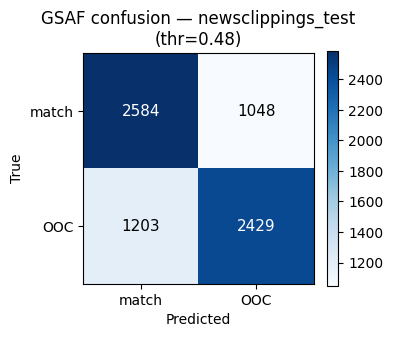

Saved E:\eve-rag\paper\figures\fusion_confusion_newsclippings_test.png


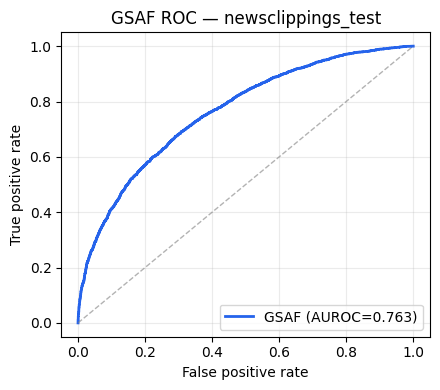

Saved E:\eve-rag\paper\figures\fusion_roc_newsclippings_test.png


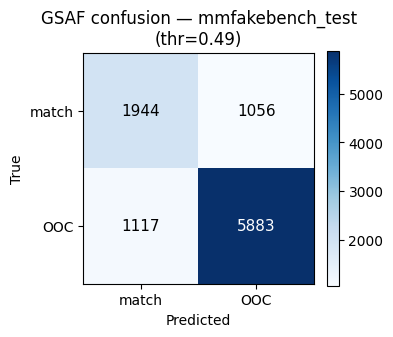

Saved E:\eve-rag\paper\figures\fusion_confusion_mmfakebench_test.png


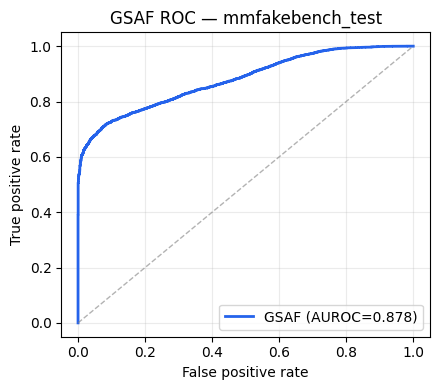

Saved E:\eve-rag\paper\figures\fusion_roc_mmfakebench_test.png


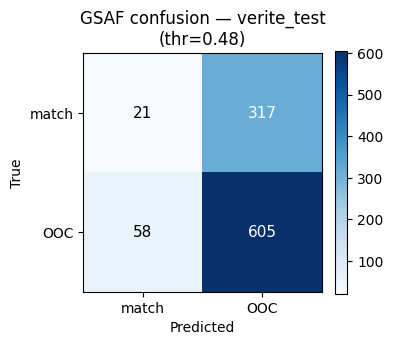

Saved E:\eve-rag\paper\figures\fusion_confusion_verite_test.png


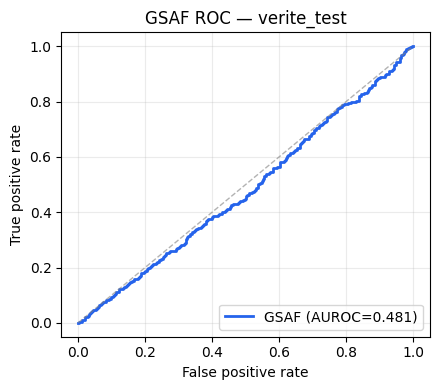

Saved E:\eve-rag\paper\figures\fusion_roc_verite_test.png


In [16]:
# === FIGURES: CONFUSION MATRICES + ROC PER DATASET ===
from sklearn.metrics import confusion_matrix, roc_curve

REPORT_SPLITS = ["newsclippings_test", "mmfakebench_test", "verite_test"]

for name in REPORT_SPLITS:
    if name not in cached_preds:
        continue
    c = cached_preds[name]
    scores = c["scores"]; labels = c["labels"]
    thr = thresholds.get(THRESHOLD_MAP.get(name, "default"), 0.5)
    pred = (scores >= thr).astype(int)

    # Confusion
    cm = confusion_matrix(labels, pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.0, 3.6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["match", "OOC"]); ax.set_yticklabels(["match", "OOC"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"GSAF confusion — {name}\n(thr={thr:.2f})")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black",
                    fontsize=11)
    plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    out = FIGURES / f"fusion_confusion_{name}.png"
    plt.savefig(out, dpi=180, bbox_inches="tight"); plt.show()
    print(f"Saved {out}")

    # ROC
    if len(np.unique(labels)) > 1:
        fpr, tpr, _ = roc_curve(labels, scores)
        auc = roc_auc_score(labels, scores)
        fig, ax = plt.subplots(figsize=(4.5, 4.0))
        ax.plot(fpr, tpr, lw=2.0, color="#2563eb", label=f"GSAF (AUROC={auc:.3f})")
        ax.plot([0, 1], [0, 1], "--", lw=1, color="gray", alpha=0.6)
        ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
        ax.set_title(f"GSAF ROC — {name}"); ax.legend(loc="lower right")
        ax.grid(alpha=0.25)
        plt.tight_layout()
        out = FIGURES / f"fusion_roc_{name}.png"
        plt.savefig(out, dpi=180, bbox_inches="tight"); plt.show()
        print(f"Saved {out}")


In [17]:
# === FINAL SUMMARY ===
print("=" * 70)
print(" FUSION TRAINING COMPLETE")
print("=" * 70)
print(f"  Model checkpoint  : {FUSION_CACHE / 'fusion_model.pt'}")
print(f"  Predictions       : {FUSION_CACHE / 'fusion_predictions.csv'}")
print(f"  Thresholds        : {FUSION_CACHE / 'fusion_thresholds.json'}")
print(f"  Train history     : {FUSION_CACHE / 'fusion_train_history.csv'}")
print(f"  Results table     : {TABLES / 'fusion_results.csv'}")
print(f"  Ablation table    : {TABLES / 'ablation_results.csv'}")
print(f"  Bar chart         : {FIGURES / 'fusion_summary_bar.png'}")
print(f"  Gate distribution : {FIGURES / 'fusion_gate_distribution.png'}")
print()
print("Headline numbers (default GSAF, tuned thresholds):")
hl = ablation_df[ablation_df["ablation"] == "default"][
    ["dataset", "acc", "f1_macro", "auroc"]
].sort_values("dataset")
display(hl)
print("\nNext: 07_eval/newsclippings_eval, 07_eval/cross_dataset_eval, 07_eval/ablations.")


 FUSION TRAINING COMPLETE
  Model checkpoint  : E:\eve-rag\cache\fusion\fusion_model.pt
  Predictions       : E:\eve-rag\cache\fusion\fusion_predictions.csv
  Thresholds        : E:\eve-rag\cache\fusion\fusion_thresholds.json
  Train history     : E:\eve-rag\cache\fusion\fusion_train_history.csv
  Results table     : E:\eve-rag\paper\tables\fusion_results.csv
  Ablation table    : E:\eve-rag\paper\tables\ablation_results.csv
  Bar chart         : E:\eve-rag\paper\figures\fusion_summary_bar.png
  Gate distribution : E:\eve-rag\paper\figures\fusion_gate_distribution.png

Headline numbers (default GSAF, tuned thresholds):


,dataset,acc,f1_macro,auroc
3,mmfakebench_test,78.27,74.28,87.83
2,mmfakebench_val_tune,82.00,79.18,89.92
1,newsclippings_test,69.01,69.00,76.32
0,newsclippings_val,69.15,69.13,76.01
4,verite_test,62.54,43.21,48.13



Next: 07_eval/newsclippings_eval, 07_eval/cross_dataset_eval, 07_eval/ablations.
